<a href="https://colab.research.google.com/github/harshitasdev8/SuSiE-Testing/blob/main/SuSiE_Comparative_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
install.packages("susieR", repos = "https://cloud.r-project.org")
library(susieR)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/susieR_0.14.2.tar.gz'
Content type 'application/x-gzip' length 2303754 bytes (2.2 MB)
downloaded 2.2 MB


The downloaded source packages are in
	‘/tmp/RtmpkSe9Ub/downloaded_packages’


$L2
[1] 653

$L1
[1] 773 777

$L3
 [1] 362 365 372 373 374 379 381 383 384 386 387 388 389 391 392 396 397 398 399
[20] 400 401 403 404 405 407 408 415

[1] 403 653 773


HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.


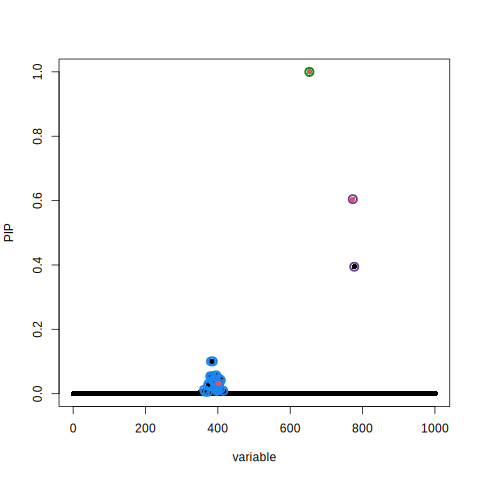

In [ ]:
%%R
data(N3finemapping)
X <- N3finemapping$X #table of geneotypes (each column is one SNP each row is a person)
y <- N3finemapping$Y[, 1] #trait measured for each person
fit <- susie(X, y, L = 10)
print(fit$sets$cs)                 # credible sets
pip <- susie_get_pip(fit)          # per-SNP PIPs : how likely is this SNP to be causal
print(which(N3finemapping$true_coef[, 1] != 0))   # true causal SNPs
susie_plot(fit, y = "PIP", b = N3finemapping$true_coef[, 1])

In [ ]:
%%R
library(susieR)
data(N3finemapping)
X <- N3finemapping$X          # genotype matrix (people x SNPs)
p <- ncol(X)

# ---- Scores one method on one simulated locus ----
# score  = one number per SNP (higher = more likely causal)
# causal = positions of the true causal SNPs
evaluate <- function(score, causal) {
  ranks <- rank(-score, ties.method = "min")[causal]   # rank 1 = top pick
  ord   <- order(-score)
  is_c  <- ord %in% causal
  prec  <- cumsum(is_c) / seq_along(is_c)
  data.frame(
    best_rank   = min(ranks),                 # rank of the best-placed true causal
    median_rank = median(ranks),
    top1        = mean(ranks <= 1),           # fraction of true causals ranked #1
    top5        = mean(ranks <= 5),
    top10       = mean(ranks <= 10),
    avg_prec    = sum(prec[is_c]) / length(causal)   # area under precision-recall
  )
}

# ---- Simulates a phenotype with known causal SNPs ----
simulate_locus <- function(X, n_causal, pve) {
  causal <- sample(ncol(X), n_causal)
  beta <- rep(0, ncol(X)); beta[causal] <- rnorm(n_causal)
  g <- as.vector(X %*% beta)
  y <- g + rnorm(nrow(X), sd = sqrt(var(g) * (1 - pve) / pve))
  list(y = y, causal = causal)
}

# ---- Computes z-scores (the marginal association of each SNP) ----
get_z <- function(X, y) {
  ur <- univariate_regression(X, y)
  ur$betahat / ur$sebetahat
}



In [ ]:
# ==== GEFM HERE  ====
# goal: return one number per SNP, higher = more likely causal.

my_collision_score <- function(X, y) {
  abs(get_z(X, y))
}

In [ ]:
%%R
set.seed(1)
n_sims <- 100          # more is better; 100 takes a few minutes
results <- list(); cs_results <- list()

for (i in 1:n_sims) {
  n_causal <- sample(1:3, 1)
  sim <- simulate_locus(X, n_causal, pve = 0.05)
  y <- sim$y; causal <- sim$causal

  z   <- get_z(X, y)
  fit <- susie(X, y, L = 10, verbose = FALSE)

  results[[length(results)+1]] <- cbind(sim = i, n_causal = n_causal, method = "SuSiE",     evaluate(fit$pip, causal))
  results[[length(results)+1]] <- cbind(sim = i, n_causal = n_causal, method = "abs(z)",    evaluate(abs(z), causal))
  results[[length(results)+1]] <- cbind(sim = i, n_causal = n_causal, method = "Collision", evaluate(my_collision_score(X, y), causal))

  # SuSiE credible set coverage and size (only if it found any sets)
  cs <- fit$sets$cs
  if (!is.null(cs)) {
    cs_results[[length(cs_results)+1]] <- data.frame(
      sim = i,
      size = sapply(cs, length),
      covers = sapply(cs, function(s) any(s %in% causal)))
  }
}
res <- do.call(rbind, results)
cs_res <- do.call(rbind, cs_results)

HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credible set (CS)calculations.
HINT: For an X with many columns, please consider installingthe Rfast package for more efficient credibl

     method best_rank median_rank      top1      top5 top10  avg_prec
1    abs(z)      2.86      66.055 0.3466667 0.5983333  0.67 0.4538025
2 Collision      2.86      66.055 0.3466667 0.5983333  0.67 0.4538025
3     SuSiE      2.97      61.260 0.3450000 0.6100000  0.69 0.4470604

SuSiE credible set coverage: 0.9846154 
SuSiE credible set median size: 5 


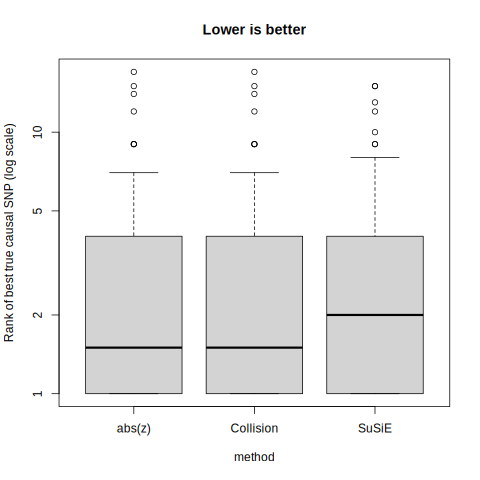

In [ ]:
%%R
# Average across simulations, one row per method
print(aggregate(cbind(best_rank, median_rank, top1, top5, top10, avg_prec) ~ method,
                data = res, FUN = mean))

# SuSiE credible sets: coverage should be near 0.95, size smaller is better
cat("\nSuSiE credible set coverage:", mean(cs_res$covers), "\n")
cat("SuSiE credible set median size:", median(cs_res$size), "\n")

# Rank of the best true causal SNP (lower = better)
boxplot(best_rank ~ method, data = res, log = "y",
        ylab = "Rank of best true causal SNP (log scale)", main = "Lower is better")